# Retail sales exploratory analysis
Explore order values, the relationship between discounts and profit margins, and weekday/weekend sales using the accompanying dataset. Findings are descriptive; correlation does not establish causation.

Run from the repository root or this project folder. Install the packages in `requirements.txt` first.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print ("Libraries imported successfully!")

Libraries imported successfully!


In [10]:
from pathlib import Path

# Works from the project folder or repository root.
candidates = [Path('retail_sales_dataset.csv'),
              Path('projects/retail-sales/retail_sales_dataset.csv')]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError('Open this notebook from the repository root or the retail-sales folder.')
df = pd.read_csv(data_path)

print('Dataset shape:', df.shape)
display(df.head())

Dataset shape: (1800, 17)


,Order_ID,Order_Date,Customer_ID,Region,City,Sales_Channel,Product_ID,Product_Name,Product_Category,Quantity,Unit_Price_INR,Discount_Pct,Sales_Revenue_INR,Unit_Cost_INR,Profit_INR,Order_Year,Order_Month
0,ORD-00001,2024-01-26,CUST-0567,Central,Indore,Retail Store,PRD-004,Coffee Maker,Home & Living,2,4499,0.10,8098.20,2500.0,3098.20,2024,Jan
1,ORD-00002,2024-01-28,CUST-0900,West,Mumbai,Retail Store,PRD-012,Yoga Mat,Sports & Outdoors,2,1299,0.00,2598.00,650.0,1298.00,2024,Jan
2,ORD-00003,2023-06-08,CUST-0122,Central,Indore,Online,PRD-014,Water Bottle,Sports & Outdoors,2,799,0.10,1438.20,310.0,818.20,2023,Jun
3,ORD-00004,2023-05-03,CUST-0738,North,Jaipur,Retail Store,PRD-011,Skin Care Kit,Beauty & Personal Care,1,2199,0.15,1869.15,1050.0,819.15,2023,May
4,ORD-00005,2024-05-01,CUST-0110,East,Kolkata,Online,PRD-002,Smart Watch,Electronics,1,4999,0.00,4999.00,3000.0,1999.00,2024,May


In [11]:
print ("Customer Spending Summary")

print(df["Sales_Revenue_INR"].describe())

Customer Spending Summary
count     1800.000000
mean      4854.562472
std       4399.656846
min        679.150000
25%       1999.000000
50%       3499.000000
75%       5998.000000
max      44995.000000
Name: Sales_Revenue_INR, dtype: float64


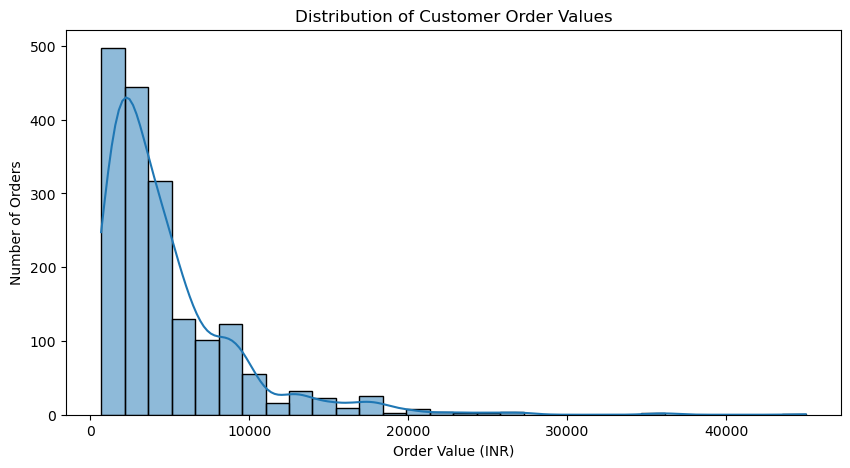

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Sales_Revenue_INR",
    bins=30,
    kde=True
)

plt.title("Distribution of Customer Order Values")
plt.xlabel("Order Value (INR)")
plt.ylabel("Number of Orders")

plt.show()

In [13]:
print(df.columns.tolist())

['Order_ID', 'Order_Date', 'Customer_ID', 'Region', 'City', 'Sales_Channel', 'Product_ID', 'Product_Name', 'Product_Category', 'Quantity', 'Unit_Price_INR', 'Discount_Pct', 'Sales_Revenue_INR', 'Unit_Cost_INR', 'Profit_INR', 'Order_Year', 'Order_Month']


In [15]:
df["Profit_Margin"] = (
    df["Profit_INR"] / df["Sales_Revenue_INR"]
) * 100

correlation = df["Discount_Pct"].corr(
    df["Profit_Margin"]
)

print("Discount vs Profit Margin Correlation:", round(correlation, 3))

Discount vs Profit Margin Correlation: -0.471


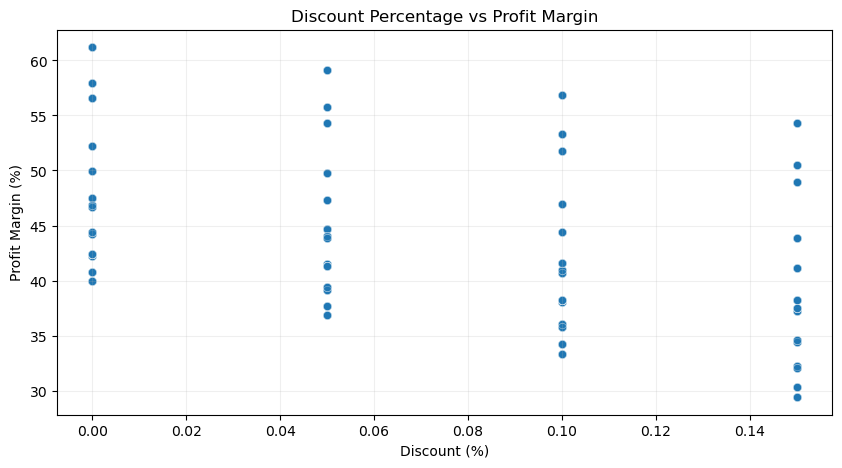

In [16]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="Discount_Pct",
    y="Profit_Margin",
    alpha=0.5
)

plt.title("Discount Percentage vs Profit Margin")
plt.xlabel("Discount (%)")
plt.ylabel("Profit Margin (%)")
plt.grid(alpha=0.2)

plt.show()

In [17]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

df["Day_Type"] = df["Order_Date"].dt.dayofweek.apply(
    lambda x: "Weekend" if x >= 5 else "Weekday"
)

df[["Order_Date", "Day_Type"]].head()

,Order_Date,Day_Type
0,2024-01-26,Weekday
1,2024-01-28,Weekend
2,2023-06-08,Weekday
3,2023-05-03,Weekday
4,2024-05-01,Weekday


In [18]:
day_analysis = df.groupby("Day_Type").agg(
    Total_Orders=("Order_ID", "nunique"),
    Total_Revenue=("Sales_Revenue_INR", "sum"),
    Average_Order_Value=("Sales_Revenue_INR", "mean")
).round(2)

display(day_analysis)

,Total_Orders,Total_Revenue,Average_Order_Value
Day_Type,,,
Weekday,1288,6322429.85,4908.72
Weekend,512,2415782.60,4718.33


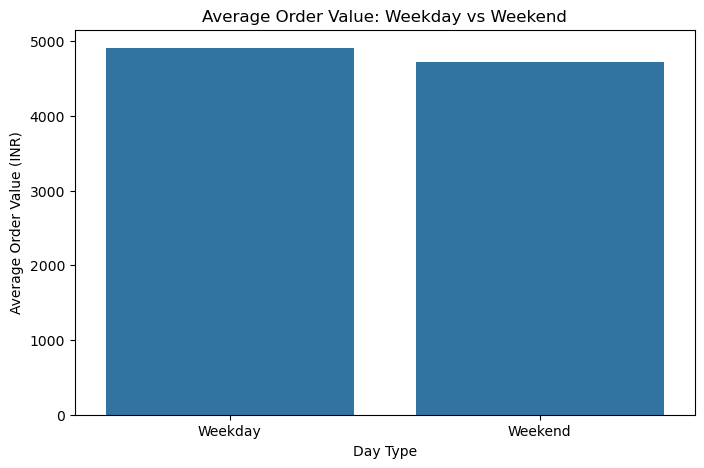

In [19]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Day_Type",
    y="Sales_Revenue_INR",
    estimator="mean",
    errorbar=None
)

plt.title("Average Order Value: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Order Value (INR)")

plt.show()